<a href="https://colab.research.google.com/github/nikepb01/ComputerVision_Colab/blob/main/7%EA%B0%95_8%EA%B0%95_%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **7주차_실습_이미지 필터 실습**

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


**02.1 평균 블러링 필터**

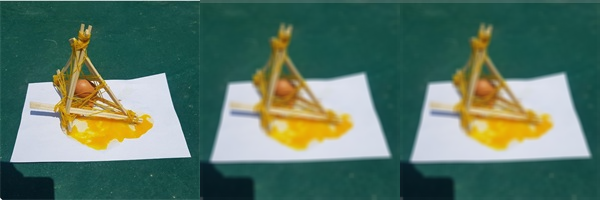

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/egg_drop_200x200.jpg' )

#커널 직접 구현
kernel = np.array([[0.04,0.04,0.04,0.04,0.04],
                   [0.04,0.04,0.04,0.04,0.04],
                   [0.04,0.04,0.04,0.04,0.04],
                   [0.04,0.04,0.04,0.04,0.04],
                   [0.04,0.04,0.04,0.04,0.04]])
#커널 간편 구현
#kernel = np.ones((5,5))/25

#openCV 필터2D 함수를 사용
blurred1 = cv2.filter2D(image, -1, kernel)

#openCV 블러링 함수를 사용
blurred2 = cv2.blur(image,(5,5))


blurred_images = np.hstack([image,blurred1,blurred2])
cv2_imshow(blurred_images)

**02.2 가우시안 블러링 필터**

원본, 가우시안필터 직접생성, getGaussianKernel(), cv2.GaussianBlur()


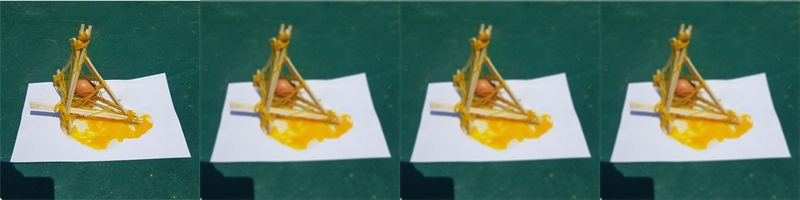

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/egg_drop_200x200.jpg')


#가우시안 커널을 직접 만들기
kernel1 = np.array([[1,2,1],
                    [2,4,2],
                    [1,2,1]])*(1/16)
blurred1 = cv2.filter2D(image, -1, kernel1)

#OpenCV에서 제공하는 가우시안 함수를 사용해 필터에 적용
#cv2.getGaussianKernel()함수는 1차원 배열이기 때문에 K*K.T 형식으로 사용
kernel2 = cv2.getGaussianKernel(3,0)
blurred2 = cv2.filter2D(image, -1, kernel2*kernel2.T)

#OpenCV에서 제공하는 가우시안 필터 함수 사용
blurred3 = cv2.GaussianBlur(image,(3,3),0)

print("원본, 가우시안필터 직접생성, getGaussianKernel(), cv2.GaussianBlur()")
blurred_images = np.hstack([image,blurred1,blurred2,blurred3])
cv2_imshow(blurred_images)

**02.3 미디언 블러링 필터**

original, 3, 5, 7


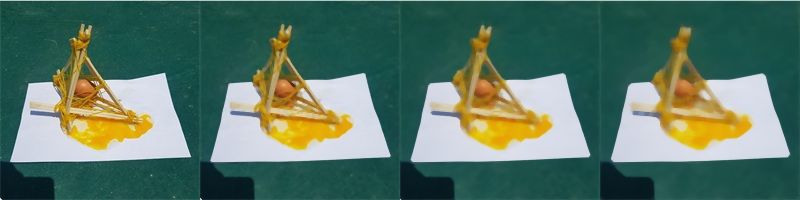

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/egg_drop_200x200.jpg')

medianBlurred = np.hstack([
  image,
	cv2.medianBlur(image, 3),
	cv2.medianBlur(image, 5),
	cv2.medianBlur(image, 7)])

print("original, 3, 5, 7")
cv2_imshow(medianBlurred)

**02.4 바이레터럴 필터**

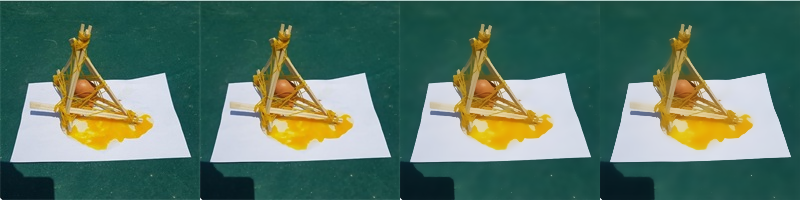

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/egg_drop_200x200.jpg')

bilateralFiltered = np.hstack([
  image,
	cv2.bilateralFilter(image, 3, 21, 21),
	cv2.bilateralFilter(image, 9, 41, 41),
	cv2.bilateralFilter(image, 11, 61, 61)])

cv2_imshow(bilateralFiltered)

blurred images


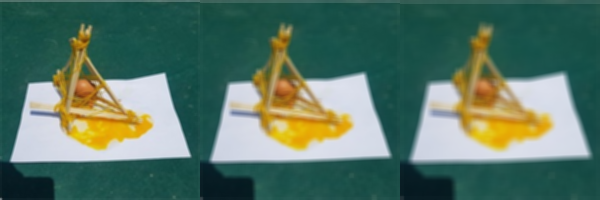

gaussian blurred images


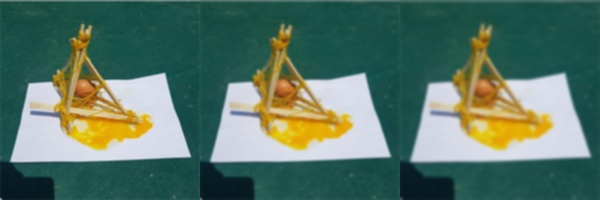

median blurred images


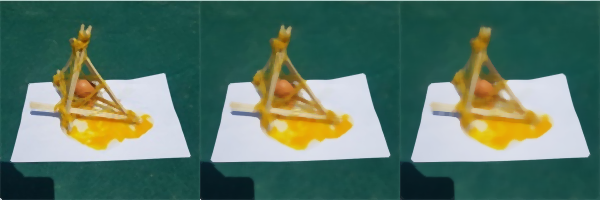

bilateral filtered images


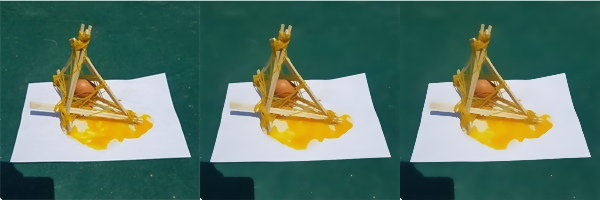

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/egg_drop_200x200.jpg')
#image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/saltnpepper300x200.jpg')
#image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/saltnpepper_color150x150.jpg')

print("blurred images")
blurred = np.hstack([
	cv2.blur(image, (3, 3)),
	cv2.blur(image, (5, 5)),
	cv2.blur(image, (7, 7))])
cv2_imshow(blurred)

print("gaussian blurred images")
GaussianBlurred = np.hstack([
	cv2.GaussianBlur(image, (3, 3), 0),
	cv2.GaussianBlur(image, (5, 5), 0),
	cv2.GaussianBlur(image, (7, 7), 0)])
cv2_imshow(GaussianBlurred)

print("median blurred images")
medianBlurred = np.hstack([
	cv2.medianBlur(image, 3),
	cv2.medianBlur(image, 5),
	cv2.medianBlur(image, 7)])
cv2_imshow(medianBlurred)

print("bilateral filtered images")
bilateralFiltered = np.hstack([
	cv2.bilateralFilter(image, 3, 21, 21),
	cv2.bilateralFilter(image, 9, 41, 41),
	cv2.bilateralFilter(image, 11, 61, 61)])
cv2_imshow(bilateralFiltered)

# 3. **샤프닝필터**

In [8]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


**03.1 기본 미분**

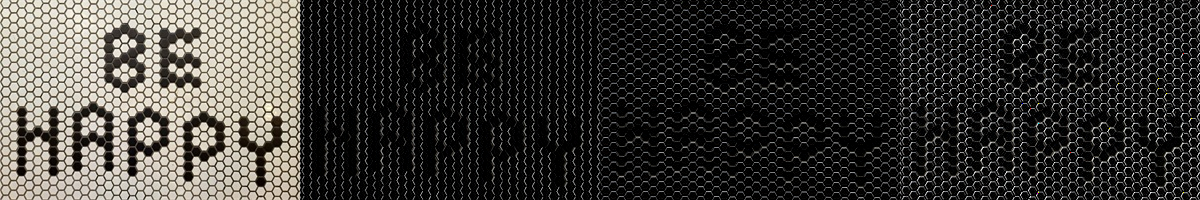

In [9]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

gx_kernel = np.array([[ -1, 1]])
gy_kernel = np.array([[ -1],
                      [ 1]])
edge_gx = cv2.filter2D(img, -1, gx_kernel)
edge_gy = cv2.filter2D(img, -1, gy_kernel)

merged = np.hstack((img, edge_gx, edge_gy, edge_gx+edge_gy ))
cv2_imshow(merged)

**03.2 로버츠 교차**

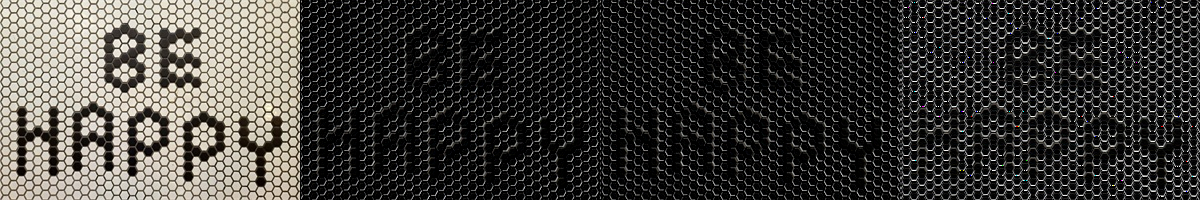

In [11]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

gx_kernel = np.array([[1,0],
                      [0,-1]])
gy_kernel = np.array([[0, 1],
                      [-1,0]])

edge_gx = cv2.filter2D(img, -1, gx_kernel)
edge_gy = cv2.filter2D(img, -1, gy_kernel)

merged = np.hstack((img, edge_gx, edge_gy, edge_gx+edge_gy))
cv2_imshow(merged)

**03.3 프리윗 필터**

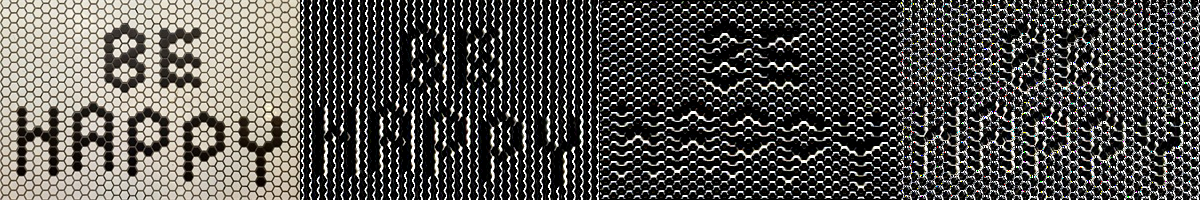

In [12]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')


gx_k = np.array([[-1,0,1],
                 [-1,0,1],
                 [-1,0,1]])

gy_k = np.array([[-1,-1,-1],
                 [0,0,0],
                 [1,1,1]])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

merged = np.hstack((img, edge_gx, edge_gy, edge_gx+edge_gy))
cv2_imshow(merged)

**03.4 소벨 필터**

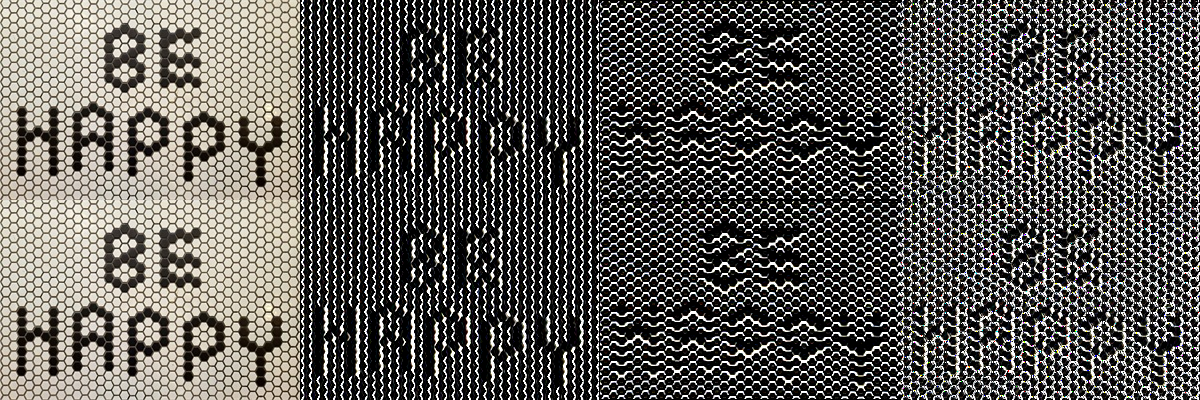

In [13]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

gx_k = np.array([[-1,0,1],
                 [-2,0,2],
                 [-1,0,1]])

gy_k = np.array([[-1,-2,-1],
                 [0,0,0],
                 [1,2,1]])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

# 소벨 openCV API
# cv2.Sobel(입력 이미지, 출력 영상의 dtype, dx,dy의 미분 차수(0,1,2) 둘 다 0은 안됨, ksize는 (1,3,5,7 중 선택) )
sobelx = cv2.Sobel(img, -1, 1, 0, ksize=3)
sobely = cv2.Sobel(img, -1, 0, 1, ksize=3)

merged1 = np.hstack((img, edge_gx, edge_gy, edge_gx+edge_gy))
merged2 = np.hstack((img, sobelx, sobely, sobelx+sobely))
merged = np.vstack((merged1, merged2))
cv2_imshow(merged)

**03.5 샤르 필터**

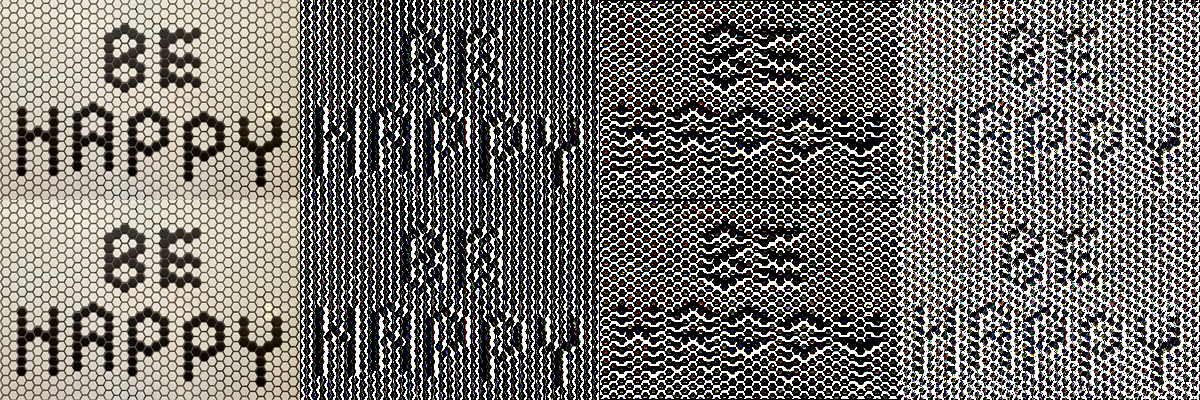

In [14]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

gx_k = np.array([[-3,0,3],
                 [-10,0,10],
                 [-3,0,3]])

gy_k = np.array([[-3,-10,-3],
                 [0,0,0],
                 [3,10,3]])

edge_gx = cv2.filter2D(img, -1, gx_k)
edge_gy = cv2.filter2D(img, -1, gy_k)

# 샤르 API
scharrx = cv2.Scharr(img, -1, 1, 0)
scharry = cv2.Scharr(img, -1, 0, 1)


merged1 = np.hstack((img, edge_gx, edge_gy, edge_gx+edge_gy))
merged2 = np.hstack((img, scharrx, scharry, scharrx+scharry))
merged = np.vstack((merged1, merged2))
cv2_imshow(merged)

**03.6 라플라시안 필터**

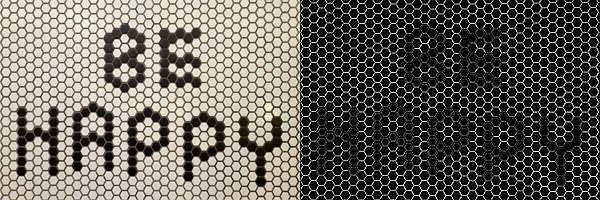

In [15]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

edge = cv2.Laplacian(img, -1)

# 결과 출력
merged = np.hstack((img, edge))
cv2_imshow(merged)

**03.7 케니 엣지 검출 필터**

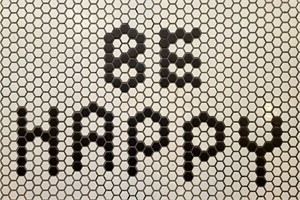

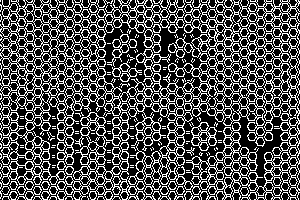

In [16]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg')

#cv2.Canny(이미지, 스레시홀드 최소/최대 값)
edges = cv2.Canny(img,100,200)

cv2_imshow(img)
cv2_imshow(edges)

# **04 모폴로지(morphology)**

**04.1 침식(erosion) 연산**

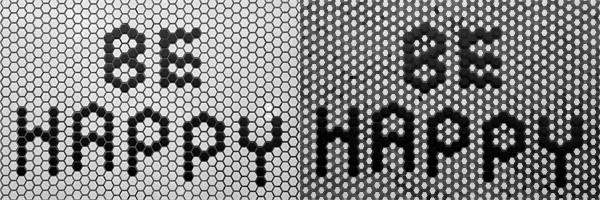

In [17]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg', cv2.IMREAD_GRAYSCALE)

# 구조화 요소 커널과 사각형 (3x3) 생성
k = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))

erosion = cv2.erode(img, k)

merged = np.hstack((img, erosion))
cv2_imshow(merged)


**04.2 팽창(dilatation) 연산**

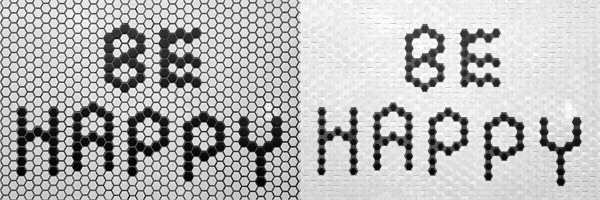

In [18]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg', cv2.IMREAD_GRAYSCALE)

# 구조화 요소 커널과 사각형 (3x3) 생성
k = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
dst = cv2.dilate(img, k)

merged = np.hstack((img, dst))
cv2_imshow(merged)

**04.3 열림(opening)연산**

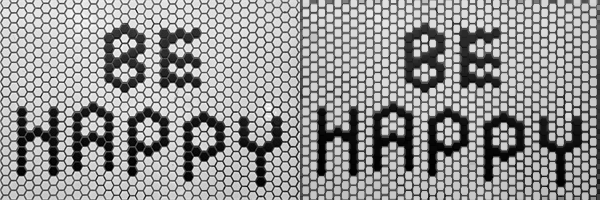

In [19]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg', cv2.IMREAD_GRAYSCALE)

# 구조화 요소 커널, 사각형 (5x5) 생성
k = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, k)

merged = np.hstack((img, opening))
cv2_imshow(merged)

**04.3 닫힘(closing) 연산**

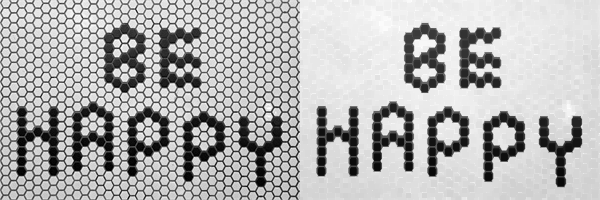

In [20]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/tile.jpg', cv2.IMREAD_GRAYSCALE)

# 구조화 요소 커널, 사각형 (5x5) 생성
k = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))
closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, k)

merged = np.hstack((img, closing))
cv2_imshow(merged)
